In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Ocultar todas las advertencias (warnings)
warnings.filterwarnings('ignore')

# Estilo visual para gráficos de series temporales
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

# Generación de datos de ventas diarias durante 2 años (2024 - 2025)
np.random.seed(42)
fechas = pd.date_range(start='2024-01-01', end='2025-12-31', freq='D')
n_dias = len(fechas)

# Creación de tendencia lineal + variaciones semanales + ruido aleatorio
tendencia = np.linspace(1000, 3500, n_dias)
estacionalidad_semanal = np.sin(np.arange(n_dias) * (2 * np.pi / 7)) * 400
ruido = np.random.normal(0, 250, n_dias)

ingresos = tendencia + estacionalidad_semanal + ruido
ingresos = np.maximum(ingresos, 500) # Evitamos valores negativos o no realistas

df_tiempo = pd.DataFrame({
    'Fecha': fechas,
    'Ingresos_Diarios': np.round(ingresos, 2),
    'Pedidos': np.random.randint(15, 80, size=n_dias)
})

# Guardar dataset en la carpeta data del proyecto 2
df_tiempo.to_csv('../data/ventas_diarias_2024_2025.csv', index=False)
print("¡Dataset de Series de Tiempo creado exitosamente!")
df_tiempo.head()

¡Dataset de Series de Tiempo creado exitosamente!


,Fecha,Ingresos_Diarios,Pedidos
0,2024-01-01,1124.18,52
1,2024-01-02,1281.59,48
2,2024-01-03,1558.74,31
3,2024-01-04,1564.58,51
4,2024-01-05,781.61,39


In [6]:
# Convertir columna Fecha a datetime e instalarla como índice
df_tiempo['Fecha'] = pd.to_datetime(df_tiempo['Fecha'])
df_tiempo.set_index('Fecha', inplace=True)

print("--- Estructura del DataFrame con DatetimeIndex ---")
print(df_tiempo.info())
print("\nRango de fechas:", df_tiempo.index.min(), "a", df_tiempo.index.max())
df_tiempo.head()

--- Estructura del DataFrame con DatetimeIndex ---
<class 'pandas.DataFrame'>
DatetimeIndex: 731 entries, 2024-01-01 to 2025-12-31
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Ingresos_Diarios  731 non-null    float64
 1   Pedidos           731 non-null    int32  
dtypes: float64(1), int32(1)
memory usage: 14.3 KB
None

Rango de fechas: 2024-01-01 00:00:00 a 2025-12-31 00:00:00


,Ingresos_Diarios,Pedidos
Fecha,,
2024-01-01,1124.18,52
2024-01-02,1281.59,48
2024-01-03,1558.74,31
2024-01-04,1564.58,51
2024-01-05,781.61,39


--- Resumen de Ventas Mensuales y Crecimiento MoM ---
            Ingresos_Mensuales  Pedidos  Crecimiento_MoM_%
Fecha                                                     
2024-01-31            32246.82     1480                NaN
2024-02-29            32925.83     1463           2.105665
2024-03-31            38282.03     1358          16.267471
2024-04-30            41173.36     1357           7.552708
2024-05-31            45067.63     1615           9.458227
2024-06-30            48287.25     1491           7.143975
2024-07-31            53832.01     1444          11.482866
2024-08-31            54626.53     1513           1.475925
2024-09-30            55348.58     1486           1.321794
2024-10-31            63053.67     1350          13.921026
2024-11-30            64255.10     1414           1.905409
2024-12-31            67400.81     1436           4.895658


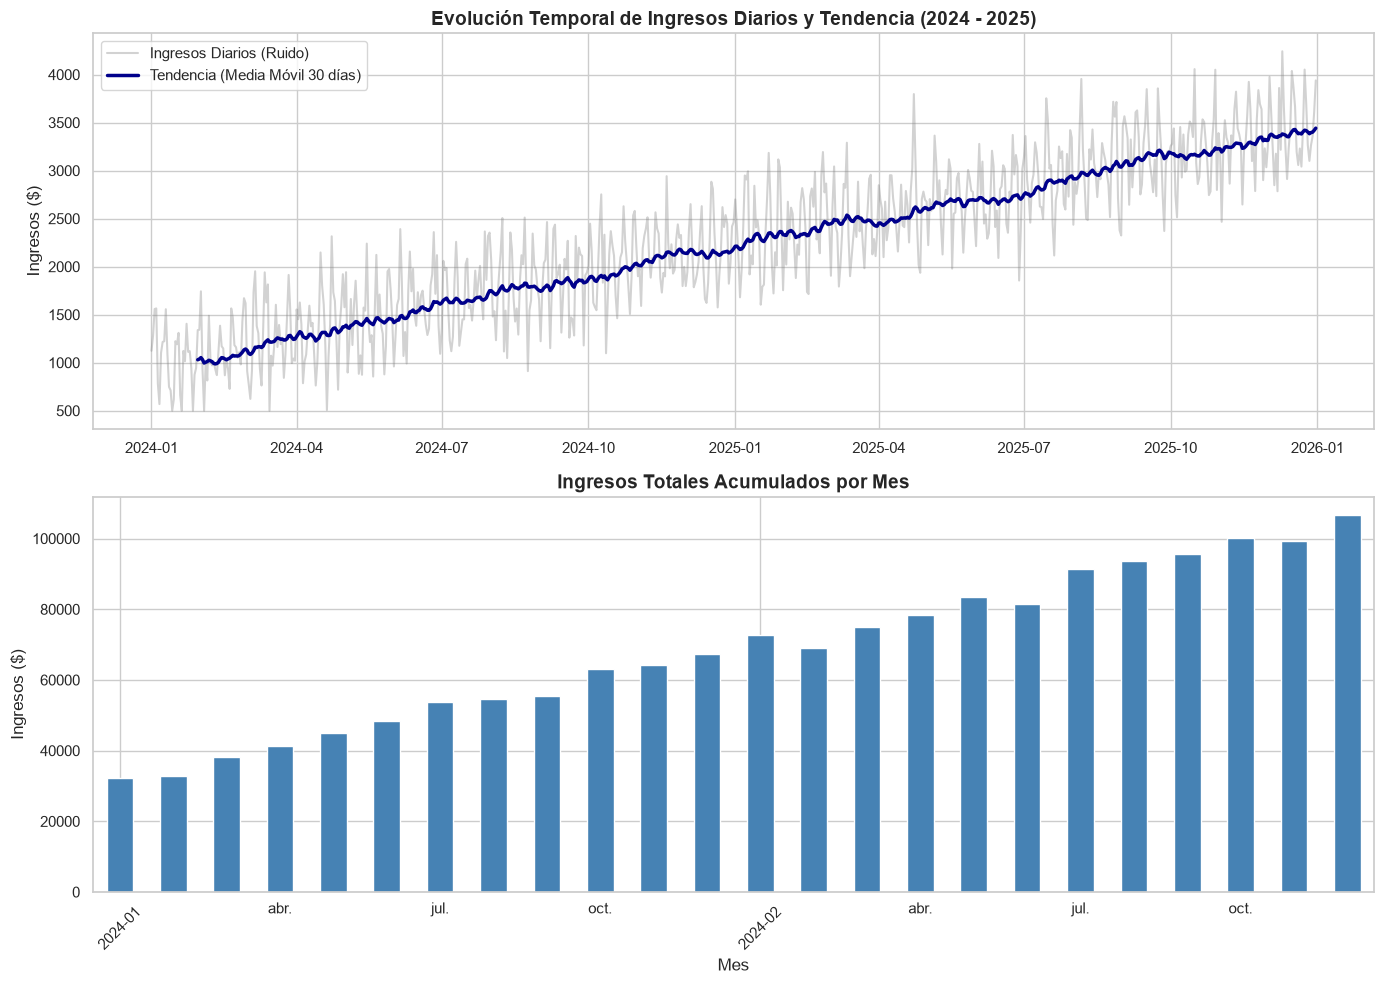


¡Gráfico exportado exitosamente en 'proyecto_2/reports/tendencia_ventas_serie_tiempo.png'!


In [7]:
# 1. Remuestreo Mensual (.resample('ME'))
# Calculamos la suma total de ingresos y pedidos por mes
df_mensual = df_tiempo.resample('ME').agg({
    'Ingresos_Diarios': 'sum',
    'Pedidos': 'sum'
}).rename(columns={'Ingresos_Diarios': 'Ingresos_Mensuales'})

# 2. Cálculo de Crecimiento Mes a Mes (MoM - Month over Month)
df_mensual['Crecimiento_MoM_%'] = df_mensual['Ingresos_Mensuales'].pct_change() * 100

# 3. Media Móvil de 30 días para la serie diaria
df_tiempo['Media_Movil_30D'] = df_tiempo['Ingresos_Diarios'].rolling(window=30).mean()

print("--- Resumen de Ventas Mensuales y Crecimiento MoM ---")
print(df_mensual.head(12))

# --- GENERACIÓN DE GRÁFICO DE SERIES TEMPORALES ---
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=False)

# Gráfico 1: Ventas Diarias vs Media Móvil de 30 días
axes[0].plot(df_tiempo.index, df_tiempo['Ingresos_Diarios'], alpha=0.35, color='gray', label='Ingresos Diarios (Ruido)')
axes[0].plot(df_tiempo.index, df_tiempo['Media_Movil_30D'], color='darkblue', linewidth=2.5, label='Tendencia (Media Móvil 30 días)')
axes[0].set_title('Evolución Temporal de Ingresos Diarios y Tendencia (2024 - 2025)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Ingresos ($)', fontsize=12)
axes[0].legend(loc='upper left')

# Gráfico 2: Ingresos Totales por Mes
df_mensual.plot(kind='bar', y='Ingresos_Mensuales', ax=axes[1], color='steelblue', legend=False)
axes[1].set_title('Ingresos Totales Acumulados por Mes', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Ingresos ($)', fontsize=12)
axes[1].set_xlabel('Mes', fontsize=12)
# Formatear etiquetas del eje X para mostrar Año-Mes
axes[1].set_xticklabels([fecha.strftime('%Y-%m') for fecha in df_mensual.index], rotation=45)

plt.tight_layout()
plt.show()

# Guardar figura en la carpeta reports del Proyecto 2
fig.savefig('../reports/tendencia_ventas_serie_tiempo.png', dpi=300)
print("\n¡Gráfico exportado exitosamente en 'proyecto_2/reports/tendencia_ventas_serie_tiempo.png'!")

--- Resumen de Ventas Mensuales y Crecimiento MoM ---
            Ingresos_Mensuales  Pedidos  Crecimiento_MoM_%
Fecha                                                     
2024-01-31            32246.82     1480                NaN
2024-02-29            32925.83     1463           2.105665
2024-03-31            38282.03     1358          16.267471
2024-04-30            41173.36     1357           7.552708
2024-05-31            45067.63     1615           9.458227
2024-06-30            48287.25     1491           7.143975
2024-07-31            53832.01     1444          11.482866
2024-08-31            54626.53     1513           1.475925
2024-09-30            55348.58     1486           1.321794
2024-10-31            63053.67     1350          13.921026
2024-11-30            64255.10     1414           1.905409
2024-12-31            67400.81     1436           4.895658


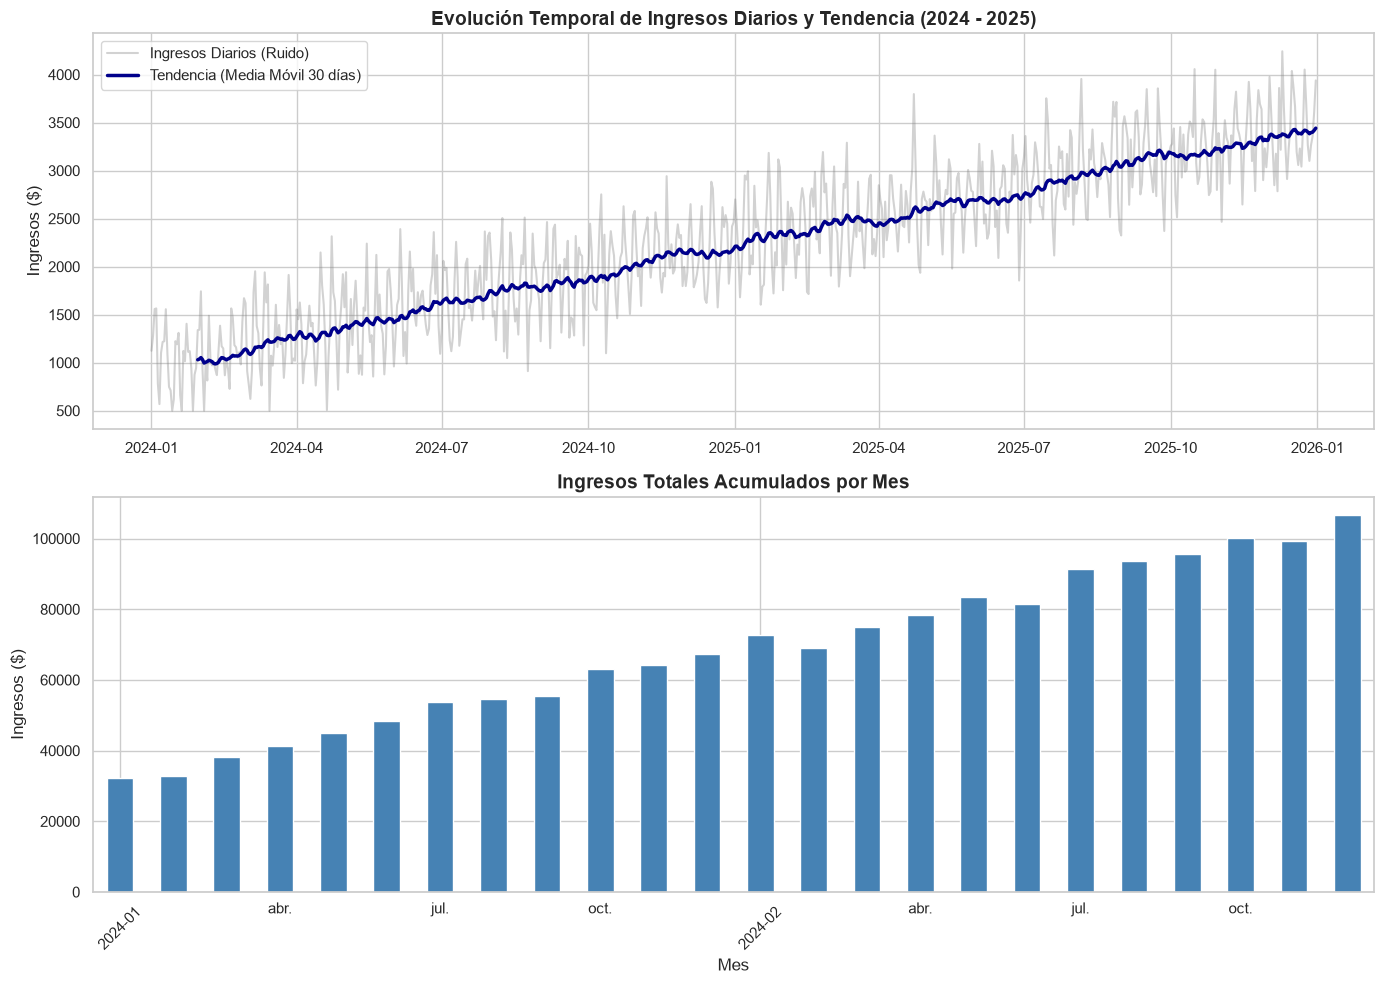


¡Gráfico exportado exitosamente en 'proyecto_2/reports/tendencia_ventas_serie_tiempo.png'!


In [8]:
# 1. Remuestreo Mensual (.resample('ME'))
df_mensual = df_tiempo.resample('ME').agg({
    'Ingresos_Diarios': 'sum',
    'Pedidos': 'sum'
}).rename(columns={'Ingresos_Diarios': 'Ingresos_Mensuales'})

# 2. Crecimiento Mes a Mes (MoM - Month over Month)
df_mensual['Crecimiento_MoM_%'] = df_mensual['Ingresos_Mensuales'].pct_change() * 100

# 3. Media Móvil de 30 días para suavizar la serie diaria
df_tiempo['Media_Movil_30D'] = df_tiempo['Ingresos_Diarios'].rolling(window=30).mean()

print("--- Resumen de Ventas Mensuales y Crecimiento MoM ---")
print(df_mensual.head(12))

# --- GENERACIÓN DE GRÁFICO DE SERIES TEMPORALES ---
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=False)

# Gráfico 1: Ventas Diarias vs Media Móvil de 30 días
axes[0].plot(df_tiempo.index, df_tiempo['Ingresos_Diarios'], alpha=0.35, color='gray', label='Ingresos Diarios (Ruido)')
axes[0].plot(df_tiempo.index, df_tiempo['Media_Movil_30D'], color='darkblue', linewidth=2.5, label='Tendencia (Media Móvil 30 días)')
axes[0].set_title('Evolución Temporal de Ingresos Diarios y Tendencia (2024 - 2025)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Ingresos ($)', fontsize=12)
axes[0].legend(loc='upper left')

# Gráfico 2: Ingresos Totales por Mes
df_mensual.plot(kind='bar', y='Ingresos_Mensuales', ax=axes[1], color='steelblue', legend=False)
axes[1].set_title('Ingresos Totales Acumulados por Mes', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Ingresos ($)', fontsize=12)
axes[1].set_xlabel('Mes', fontsize=12)
axes[1].set_xticklabels([fecha.strftime('%Y-%m') for fecha in df_mensual.index], rotation=45)

plt.tight_layout()
plt.show()

# Guardar figura en la carpeta reports del Proyecto 2
fig.savefig('../reports/tendencia_ventas_serie_tiempo.png', dpi=300)
print("\n¡Gráfico exportado exitosamente en 'proyecto_2/reports/tendencia_ventas_serie_tiempo.png'!")